# بخش اول

### type - algorithm - metric
1. regression - linear regression - MAE*, MSE, R2
2. classification - logistic regression - F1*
3. regression - linear regression - MAE*
4. classification - logistic regression - recall*, precision, F1, confusion matrix
5. regression - linear regression - MAE 
6. classification - K-means - no match

# بخش دوم
1. زیرا این معیارها برای وقتی هستند که فاصله نتیجه پیش بینی شده را از نتیجه مورد انتظار میسنجیم و نتیجه ی مورد انتظار در در این الگوریتم تعریف نشده است.
2. the data is so imbalancedthat a model always predicting 'positive' could have high accuracy but that alone doesn't mean we have got the quality we're aiming for.
3. In a regression model the data is continous. In classification it's discrete. binary or multiclass we still know the exact outcome we're expecting. it's possible to compare it to a predicted outcome by distance. in the other case is not.

# بخش سوم

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
quiz_data = pd.DataFrame({
    "study_hours": [
        4.8, 11.4, 8.9, 7.4, 2.3, 2.3, 1.2, 10.5, 7.4, 8.6, 0.7, 11.7, 10.1, 2.9, 2.6, 2.6,
        4.0, 6.5, 5.5, 3.8, 7.5, 2.1, 3.9, 4.7, 5.7, 9.5, 2.8, 6.4, 7.3, 1.0, 7.5, 2.5,
        1.2, 11.4, 11.6, 9.8, 4.0, 1.6, 8.4, 5.6, 1.9, 6.2, 0.9, 11.0, 3.5, 8.1, 4.1, 6.5,
        6.8, 2.6, 11.7, 9.4, 11.3, 10.8, 7.4, 11.1, 1.5, 2.8, 1.0, 4.2
    ],
    "videos_watched": [
        15, 12, 17, 14, 20, 23, 24, 12, 8, 14, 12, 0, 24, 6, 8, 23, 0, 11, 7, 23, 10, 18, 16, 7,
        2, 2, 0, 4, 9, 6, 8, 6, 8, 7, 11, 1, 0, 15, 22, 22, 23, 4, 2, 11, 7, 21, 2, 0, 2, 4,
        14, 13, 2, 0, 4, 22, 13, 6, 8, 14
    ],
    "practice_solved": [
        14, 25, 12, 31, 38, 31, 3, 29, 36, 22, 38, 14, 28, 35, 12, 31, 6, 21, 27, 1, 5, 27, 27, 19,
        29, 10, 27, 24, 38, 32, 0, 26, 12, 2, 38, 5, 7, 26, 8, 36, 32, 23, 14, 31, 31, 23, 11, 38,
        1, 2, 36, 16, 1, 1, 27, 22, 36, 31, 32, 0
    ],
    "quiz_score": [
        59.7, 94.2, 82.2, 83.1, 72.2, 62.8, 43.3, 97.3, 78.1, 88.6, 61.2, 86.6, 97.9, 59.2, 43.3, 72.4,
        48.4, 74.1, 66.6, 54.6, 67.3, 55.2, 68.7, 54.5, 67.1, 69.7, 47.2, 62.9, 81.4, 50.7, 64.3, 53.8,
        44.5, 88.3, 100.0, 67.1, 36.4, 59.6, 85.4, 80.9, 68.6, 69.8, 35.0, 100.0, 60.6, 82.2, 50.8, 77.4,
        55.7, 32.3, 100.0, 77.8, 76.1, 74.3, 74.4, 100.0, 55.3, 56.6, 44.6, 47.0
    ]
})
#الف
X = quiz_data[["study_hours", "videos_watched", "practice_solved"]]
y = quiz_data["quiz_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#ب
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
#ج
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")


Mean Squared Error: 37.35
R-squared: 0.90
Mean Absolute Error: 5.08


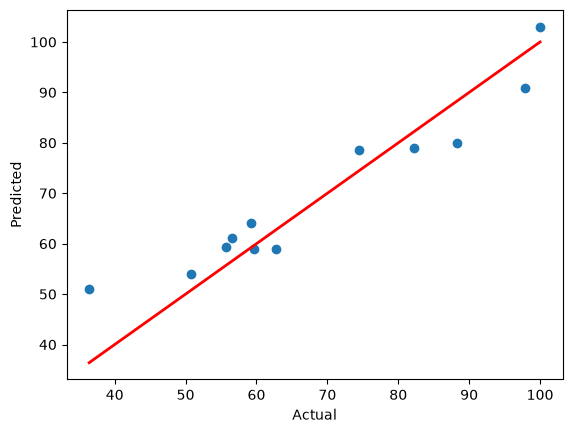

In [3]:
import matplotlib.pyplot as plt
#د
plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], lw=2, color = 'red')
plt.show()

In [4]:
#هـ
coef = model.coef_
for i, feature in enumerate(X.columns):
    print(f"Coefficient for {feature}: {coef[i]:.4f}")

Coefficient for study_hours: 4.3538
Coefficient for practice_solved: 0.6401


# بخش سوم
1. 'study hours' is the primary feature and yes it matches my observation
2. yes they are mostly near the line. if not they're outliers.
3. high r2 score is misleading as it checks in sample fit. it does garantee that the model is indeed a good fit for the current data set but we cannot say for sure that the model is gonna do well on unseen data based on this metric alone. Increasing variables can effectively increase r2 which makes the metric inreliable for measuring model quality.
4. as mentioned in the previous answer r2 increases when values increase.

In [6]:
import pandas as pd

gym_data = pd.DataFrame({
    "visits_per_month": [
        6,5,0,4,15,12,18,4,17,6,6,0,11,18,8,0,16,12,16,14,17,13,3,19,13,15,15,4,0,16,
        18,15,0,11,4,0,0,5,17,15,17,10,0,6,5,10,14,4,13,19,6,7,17,4,5,17,3,7,0,12,
        19,12,1,14,13,9,11,6,8,19,12,8,10,17,14,5,12,7,2,4,14,12,9,16,11,9,3,10,4,16
    ],
    "avg_session_min": [
        51.1,40.8,15.4,74.2,42.2,44.3,26.8,54.0,66.4,56.7,25.1,18.6,66.3,73.9,48.1,13.9,40.4,27.1,49.5,51.0,
        42.2,51.2,13.4,43.6,54.7,49.9,74.3,47.5,11.3,25.4,51.7,47.2,12.6,32.4,54.5,11.0,13.1,28.6,33.4,45.6,
        38.9,64.9,24.3,58.1,42.0,72.3,66.1,53.3,64.1,25.1,68.6,52.4,49.4,63.6,63.1,62.6,17.9,71.0,13.2,50.1,
        59.8,48.8,22.6,27.8,49.8,30.3,51.6,56.8,33.3,54.3,31.1,52.9,35.4,65.0,37.1,47.1,73.8,59.7,12.0,59.5,
        72.2,52.2,62.6,51.2,37.1,46.4,16.8,39.4,37.3,42.7
    ],
    "days_since_last_visit": [
        8,10,21,1,10,11,8,1,14,3,7,41,1,6,14,20,8,7,12,14,2,14,23,12,7,4,10,5,46,4,
        11,4,58,11,10,26,49,4,14,5,13,5,43,13,10,7,1,5,2,13,14,11,1,12,3,7,27,3,25,9,
        1,5,27,11,8,4,9,0,9,5,12,10,5,1,4,2,12,10,55,10,8,14,13,8,3,11,34,12,6,8
    ],
    "has_personal_trainer": [
        1,1,0,1,1,0,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,1,1,1,1,1,0,1,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,1,0,1,1,1,1,
        1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,0,1,1,0,0
    ],
    "churned": [
        0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,
        0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0
    ]
})

